# 17 · The real-time loop, its latency budget and the promotion gate

A decoder is only useful for a closed-loop BCI if it keeps up with the scanner and if the
feedback arrives fast enough for the user to use it. This notebook runs the real-time path of
the `fusi_realtime` workload (`realtime.py`, four Ray actors) at the 32³ grid and 10 Hz,
measures per-stage latency, and shows how `gates.py` turns those numbers plus accuracy and
leakage-check results into a promotion decision.

**Read the numbers as measurements of this machine** (CPU, Ray local mode, other processes
running). The decoder uses random weights: latency does not depend on the weights, only on the
architecture and input size. Nothing here says anything about decoding accuracy.

## Conceptual model

```
source (driver, 10 Hz clock)   one Ray actor per stage; calls queue per actor
  frame N   ─► Ingest.push ─► Preprocess.process ─► Decoder.step ─► Action.apply ─► feedback to user
  frame N+1      ─► Ingest.push ─► ...                           (stages overlap in time)
```

* **Stages.** `ingest` copies the IQ volume into a preallocated ring buffer; `preprocess` runs
  the streaming SVD clutter filter, drift removal, RETROICOR and z-score (notebook 15);
  `decode` is one KV-cached decoder step (notebook 16); `action` turns class probabilities into
  a bounded cursor velocity. The velocity is fed back to the simulated user (closed loop).
* **Latency.** Per frame: `transfer` = acquisition timestamp to ingest start (serialisation and
  scheduling), the four stage durations, and `queue_wait` between stages. **End-to-end** =
  acquisition timestamp to the end of `action`. Timestamps are wall-clock `time.time_ns()`,
  comparable across processes on one host.
* **Drop, never queue.** At 10 Hz a new volume arrives every 100 ms. If the pipeline is slower,
  a queue would grow without bound and every frame would be stale. Instead (a) the source refuses
  a frame when `max_in_flight` (3) frames are already in the pipeline (*backpressure drop*), and
  (b) a stage discards a frame already older than `late_ms` (100 ms) when it starts (*late
  drop*). Both are counted. A dropped frame's index still advances the decoder's RoPE positions.
* **Budget.** The gate caps end-to-end p99 at **130 ms**, the visual-feedback delay estimated
  in one nonhuman primate using a cursor BCI (Golub, Yu, Chase, IEEE EMBC 2012,
  doi 10.1109/EMBC.2012.6346182; one animal, one study), which the subject compensated
  by predicting the cursor; the system's added delay is capped at that figure. 130 ms is split into an **80 ms stage budget** (the sum of the
  per-stage p99s) and **50 ms headroom** for jitter. For scale, the closed-loop fUS-BMI of
  Griggs et al. (Nat. Neurosci. 2024) updated at **2 Hz** (one decision per 500 ms), so 130 ms is a much tighter
  target than that system's update interval, and a 10 Hz frame period (100 ms) is already
  shorter than the 130 ms ceiling.
* **What the clock excludes.** The acquisition timestamp is taken when the simulator hands
  over a volume. On a real scanner, beamforming, IQ reconstruction and transfer happen *before*
  that timestamp and would add to the user-visible delay.

In [1]:
import os, sys, tempfile, time, warnings
from pathlib import Path

os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")
os.environ.setdefault("ML_LOG_LEVEL", "WARNING")   # keep structlog output out of the notebook
os.environ.setdefault("RAY_DEDUP_LOGS", "1")
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
os.environ.setdefault("RAY_USAGE_STATS_ENABLED", "0")
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.precision", 4)
pd.set_option("display.width", 120)
plt.rcParams.update({"figure.dpi": 80, "figure.figsize": (7.5, 3.6), "axes.grid": True,
                     "grid.alpha": 0.3})

# Every artifact this notebook creates lives in a fresh temp dir -- never in the repo's
# data/, artifacts/ or mlflow.db.
WORK = Path(tempfile.mkdtemp(prefix="nb17_"))
T0 = time.perf_counter()
print("workspace:", WORK)

workspace: /var/folders/vx/0jy3t_qx56q4d0qpnmgs008r0000gn/T/nb17_sd7h3zqm


In [2]:
from dataclasses import replace
import torch

from ml_platform.config import PlatformConfig
from ml_platform.ray_runtime.cluster import ensure_ray, shutdown_ray
from ml_platform.workloads.fusi_realtime import preprocess as PP, gates as G
from ml_platform.workloads.fusi_realtime.config import FusiConfig
from ml_platform.workloads.fusi_realtime.models import build_decoder, save_decoder
from ml_platform.workloads.fusi_realtime.realtime import run_realtime
from ml_platform.workloads.fusi_realtime.sim import FusiSimulator
from ml_platform.workloads.fusi_realtime.splits import CheckResult

cfg = PlatformConfig.for_tests(WORK)
cfg.fusi = FusiConfig()                      # the real defaults: 32^3, 10 Hz, ensemble 8, budget 130/80 ms
fc = cfg.fusi
GRID = tuple(fc.sim.grid)
print("grid", GRID, "| rate", fc.sim.frame_rate_hz, "Hz | ensemble", fc.sim.n_ensemble)
print("realtime:", fc.realtime.model_dump())
print("gates:   ", fc.gates.model_dump())
print("cpu count:", os.cpu_count(), "| torch threads in the decoder actor:", fc.realtime.torch_threads)

grid (32, 32, 32) | rate 10.0 Hz | ensemble 8
realtime: {'seconds': 20.0, 'warmup_frames': 10, 'late_ms': 100.0, 'max_in_flight': 3, 'torch_threads': 2}
gates:    {'p99_budget_ms': 130.0, 'stage_budget_ms': 80.0, 'max_drop_fraction': 0.0, 'min_accuracy_improvement': 0.0, 'min_accuracy': 0.2}
cpu count: 10 | torch threads in the decoder actor: 2


## 1 · Assets: a calibrated preprocessor and a random-weight decoder

As in `scripts/bench_fusi_realtime.py`: the preprocessor is fitted on a separate simulated
calibration session (so its state is realistic and loadable), and the decoder has the configured
architecture with random weights. Both are written into the notebook's temp directory.

In [3]:
def calibration_assets(cfg, grid, out, n_frames=80):
    fc = cfg.fusi
    sim = FusiSimulator(fc.sim, session=800, grid=grid)
    frames = sim.run(n_frames)
    power = np.stack([PP.clutter_filter(f.iq, fc.preprocess.clutter_rank) for f in frames])
    y = PP.detrended_log(power, fc.sim.frame_rate_hz, fc.preprocess)
    card = np.array([f.cardiac_phase for f in frames]); resp = np.array([f.respiratory_phase for f in frames])
    state = PP.fit_preprocessor([("calibration", 0, n_frames, y, card, resp)], grid=grid,
                                frame_rate_hz=fc.sim.frame_rate_hz, cfg=fc.preprocess)
    ckpt = out / "decoder"; ckpt.mkdir(parents=True, exist_ok=True)
    state.save(ckpt / "preprocessor")
    torch.manual_seed(0)
    save_decoder(build_decoder(fc.decoder, grid, fc.sim.n_directions), str(ckpt / "model.pt"))
    return ckpt

t0 = time.perf_counter()
ckpt = calibration_assets(cfg, GRID, WORK)
print(f"assets in {time.perf_counter() - t0:.1f}s:", sorted(p.name for p in ckpt.iterdir()),
      "| preprocessor:", sorted(p.name for p in (ckpt / 'preprocessor').iterdir()))

assets in 0.9s: ['model.pt', 'preprocessor'] | preprocessor: ['state.json', 'state.npz']


## 2 · Run the actor pipeline

15 s of stream = 150 frames after a 10-frame warm-up (warm-up frames are excluded from the
statistics). Ray starts local with 4 CPUs; the four actors reserve 0.5 + 1 + 1 + 0.5 CPUs.

In [4]:
ensure_ray(num_cpus=4, include_dashboard=False)
t0 = time.perf_counter()
report, records = run_realtime(cfg, checkpoint=ckpt, preprocessor_dir=ckpt / "preprocessor", seconds=15.0, grid=GRID)
print(f"run took {time.perf_counter() - t0:.1f}s wall (incl. actor start-up and model load)\n")
print(report.table())
print("\nmeta:", {k: (round(v, 3) if isinstance(v, float) else v) for k, v in report.meta.items()})

2026-10-25 20:18:53,373	INFO worker.py:2024 -- Started a local Ray instance.


(raylet) [2026-10-25 20:19:02,390 E 19255 693970] (raylet) file_system_monitor.cc:116: /tmp/nbb_ray_b2f_zbxc/session_2026-10-25_20-18-50_312405_19159 is over 95% full, available space: 4.45182 GB; capacity: 460.432 GB. Object creation will fail if spilling is required.


(raylet) [2026-10-25 20:19:12,476 E 19255 693970] (raylet) file_system_monitor.cc:116: /tmp/nbb_ray_b2f_zbxc/session_2026-10-25_20-18-50_312405_19159 is over 95% full, available space: 4.40801 GB; capacity: 460.432 GB. Object creation will fail if spilling is required.


run took 19.1s wall (incl. actor start-up and model load)

stage            n      p50      p95      p99      max  (ms)
transfer       150     1.20     1.58     1.88     1.90
ingest         150     0.06     0.20     0.27     0.28
preprocess     150     1.43     1.56     1.73     1.77
decode         150     0.70     0.81     1.09     1.31
action         150     0.04     0.05     0.06     0.06
queue_wait     450     0.90     1.16     1.32     1.51
end_to_end     150     5.93     6.82     7.66     8.14
frames 150  completed 150  dropped 0 (backpressure 0, late 0)  max in flight 1  final backlog 0  achieved 10.06 Hz

meta: {'seconds': 15.0, 'late_ms': 100.0, 'max_in_flight_limit': 3, 'torch_threads': 2, 'otel_exporter': 'none', 'trials_succeeded': 0, 'trials_finished': 3, 'final_engagement': 0.807}


Reading the table: each stage row is that stage's own duration; `queue_wait` is the time frames
spend waiting for an actor between stages (mailbox + Ray scheduling); `end_to_end` is the
figure the gate uses. Because the stages overlap across frames, end-to-end is a *latency* and
not the sum of throughput costs: frame N+1 is being preprocessed while frame N is decoded.

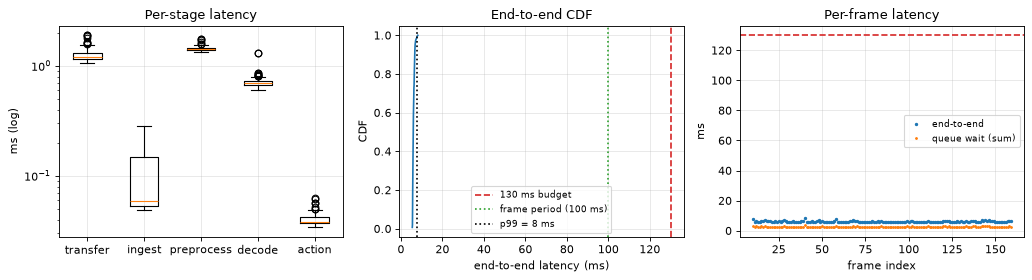

stage p99 (ms): {'transfer': 1.88, 'ingest': 0.27, 'preprocess': 1.73, 'decode': 1.09, 'action': 0.06} | sum = 5.03 (stage budget 80 ms)
end-to-end: p50 5.9, p99 7.7, max 8.1 ms over n=150 frames


In [5]:
done = [r for r in records if not r.get("dropped")]
stage_ms = {"transfer": [(r["ts"]["ingest"][0] - r["t_acq_ns"]) / 1e6 for r in done]}
for s in ("ingest", "preprocess", "decode", "action"):
    stage_ms[s] = [(r["ts"][s][1] - r["ts"][s][0]) / 1e6 for r in done]
e2e = np.array([(r["ts"]["action"][1] - r["t_acq_ns"]) / 1e6 for r in done])
wait = np.array([sum((r["ts"][b][0] - r["ts"][a][1]) / 1e6 for a, b in (("ingest", "preprocess"), ("preprocess", "decode"), ("decode", "action")))
                 for r in done])

fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
ax[0].boxplot([stage_ms[s] for s in stage_ms], tick_labels=list(stage_ms), showfliers=True)
ax[0].set(yscale="log", ylabel="ms (log)", title="Per-stage latency")
xs = np.sort(e2e); ax[1].plot(xs, np.arange(1, len(xs) + 1) / len(xs))
ax[1].axvline(fc.gates.p99_budget_ms, c="C3", ls="--", label=f"{fc.gates.p99_budget_ms:.0f} ms budget")
ax[1].axvline(1000 / fc.sim.frame_rate_hz, c="C2", ls=":", label="frame period (100 ms)")
ax[1].axvline(np.percentile(e2e, 99), c="k", ls=":", label=f"p99 = {np.percentile(e2e, 99):.0f} ms")
ax[1].set(xlabel="end-to-end latency (ms)", ylabel="CDF", title="End-to-end CDF"); ax[1].legend(fontsize=8)
idx = np.array([r["index"] for r in done])
ax[2].plot(idx, e2e, ".", ms=4, label="end-to-end"); ax[2].plot(idx, wait, ".", ms=3, label="queue wait (sum)")
ax[2].axhline(fc.gates.p99_budget_ms, c="C3", ls="--"); ax[2].set(xlabel="frame index", ylabel="ms", title="Per-frame latency"); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

stage_p99 = {s: float(np.percentile(v, 99)) for s, v in stage_ms.items()}
print("stage p99 (ms):", {k: round(v, 2) for k, v in stage_p99.items()}, "| sum =", round(sum(stage_p99.values()), 2),
      f"(stage budget {fc.gates.stage_budget_ms:.0f} ms)")
print(f"end-to-end: p50 {np.percentile(e2e, 50):.1f}, p99 {np.percentile(e2e, 99):.1f}, max {e2e.max():.1f} ms over n={len(e2e)} frames")

Sample-size caveat: with ~150 frames the p99 is determined by the one or two slowest frames, so
it is a noisy estimate; the benchmark script defaults to longer runs and a real gate decision
should use thousands of frames and several runs. The first frames after warm-up often carry
one-off costs (lazy allocations, first Ray object transfers); the `max` is a better indicator of
such events than the p99.

## 3 · The gates

`latency_gate` returns a list of failure reasons (empty = pass). It checks, in order: end-to-end
p99 ≤ 130 ms; sum of per-stage p99s ≤ 80 ms; dropped fraction ≤ `max_drop_fraction` (0 by
default: any drop fails); no backlog left in flight when the stream stops.

In [6]:
reasons = G.latency_gate(report, fc.gates)
print("latency gate on THIS run:", "PASS" if not reasons else "FAIL")
for r in reasons: print("  -", r)
print(f"(this machine, this load: e2e p99 {report.end_to_end.p99:.1f} ms vs {fc.gates.p99_budget_ms:.0f} ms; "
      f"dropped {report.n_dropped}/{report.n_frames})")

latency gate on THIS run: PASS
(this machine, this load: e2e p99 7.7 ms vs 130 ms; dropped 0/150)


The full promotion decision, `decide_promotion`, adds the dataset-level checks and accuracy:
every leakage/overfitting check must pass; test accuracy must be at least `min_accuracy` (0.2,
chance is 0.125) and beat the reference (production decoder, or the PCA + LDA baseline while
there is none) by `min_accuracy_improvement`; then the latency gate. All failing reasons are
listed, not only the first.

To show the accuracy and check logic independently of this machine's load, the scenarios below
pair example accuracy numbers (illustrative, not measured) with a *synthetic* latency report
built from generated per-frame timestamps through the same `latency_report_from_records` code
path as the real run.

In [7]:
def synth_report(decode_ms=18.0, n=300, dropped_bp=0, final_in_flight=0, seed=0):
    rng = np.random.default_rng(seed)
    recs, t = [], 1_000_000_000_000
    for i in range(n):
        a = t + i * 100_000_000
        cur = a + int(rng.gamma(4, 1.0) * 1e6)                    # transfer ~4 ms
        ts = {}
        for s, mean in (("ingest", 3.0), ("preprocess", 12.0), ("decode", decode_ms), ("action", 1.0)):
            d = int(rng.gamma(20, mean / 20) * 1e6)
            ts[s] = (cur, cur + d); cur += d + int(rng.gamma(2, 1.0) * 1e6)   # ~2 ms queue wait
        recs.append({"index": i, "t_acq_ns": a, "ts": ts})
    return G.latency_report_from_records(recs, frame_rate_hz=10.0, grid=GRID, n_frames=n + dropped_bp,
                                         n_dropped_backpressure=dropped_bp, max_in_flight=3,
                                         final_in_flight=final_in_flight, duration_s=n / 10.0)

ok_checks = [CheckResult(n, True, "ok") for n in ("sessions_disjoint", "temporal_gap", "no_window_overlap",
                                                   "preprocessing_fit_on_train_only", "feature_schema")]
leak = [*ok_checks[:1], CheckResult("temporal_gap", False, "min gap -6 frames (sub00_ses00 train vs val); required 50"), *ok_checks[2:]]

scenarios = {
    "1 healthy (synthetic latency)":        dict(acc=0.62, ref=0.45, checks=ok_checks, lat=synth_report()),
    "2 leakage check failed":                 dict(acc=0.91, ref=0.45, checks=leak,      lat=synth_report()),
    "3 does not beat baseline":               dict(acc=0.44, ref=0.45, checks=ok_checks, lat=synth_report()),
    "4 accurate but slow decoder (150 ms)":   dict(acc=0.70, ref=0.45, checks=ok_checks, lat=synth_report(decode_ms=150.0)),
    "5 drops and a backlog":                  dict(acc=0.70, ref=0.45, checks=ok_checks, lat=synth_report(dropped_bp=6, final_in_flight=2)),
    "6 accuracy below the floor":             dict(acc=0.15, ref=0.10, checks=ok_checks, lat=synth_report()),
    "7 this run's measured latency, acc 0.62": dict(acc=0.62, ref=0.45, checks=ok_checks, lat=report),
}
rows = []
for name, s in scenarios.items():
    d = G.decide_promotion(candidate_acc=s["acc"], reference_acc=s["ref"], reference="baseline",
                           latency=s["lat"], checks=s["checks"], cfg=fc.gates)
    rows.append({"scenario": name, "acc": s["acc"], "e2e p99 ms": s["lat"].end_to_end.p99, "passed": d.passed,
                 "reasons": " | ".join(d.reasons) or "-"})
pd.set_option("display.max_colwidth", 160)
pd.DataFrame(rows).set_index("scenario")

,acc,e2e p99 ms,passed,reasons
scenario,,,,
1 healthy (synthetic latency),0.62,57.9410,True,-
2 leakage check failed,0.91,57.9410,False,check temporal_gap failed: min gap -6 frames (sub00_ses00 train vs val); required 50
3 does not beat baseline,0.44,57.9410,False,test accuracy 0.440 does not beat baseline 0.450
4 accurate but slow decoder (150 ms),0.70,270.3146,False,end-to-end p99 270.3 ms > budget 130 ms | sum of stage p99s 277.5 ms > stage budget 80 ms
5 drops and a backlog,0.70,57.9410,False,dropped 6/306 frames (2.0% > 0.0%) | backlog: 2 frames still in flight at stop
6 accuracy below the floor,0.15,57.9410,False,test accuracy 0.150 < minimum 0.200
"7 this run's measured latency, acc 0.62",0.62,7.6643,True,-


Scenario 2 is the important one: a 0.91 accuracy is *not promoted* because the
leakage check failed; a failed check makes the accuracy uninterpretable (notebook 15). Scenario
4 shows the budget in action: a decoder step of 150 ms alone breaks both the end-to-end p99 and
the stage-sum budget. Scenario 7 reuses the measured report, so its outcome depends on how busy
this machine was during the run.

## 4 · Why drop instead of queue

A single-stage model of the pipeline: frames arrive every 100 ms; the stage needs 130 ms per
frame (slower than the source, as an overloaded decoder would be). With an unbounded queue the
latency of frame $k$ grows as $130 + 30k$ ms without limit. With drop-not-queue (at most 3
frames in flight, frames older than 100 ms discarded on start) latency stays bounded at the cost
of a counted fraction of frames.

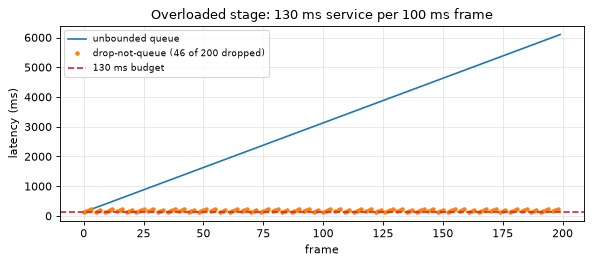

queue: latency of frame 199 = 6100 ms;  drop: max latency 230 ms, dropped 23%


In [8]:
def simulate(policy, service=130.0, period=100.0, n=200, max_in_flight=3, late=100.0):
    free_at, lat, dropped, busy_until = 0.0, [], 0, []
    for k in range(n):
        t = k * period
        busy_until = [b for b in busy_until if b > t]                 # frames still in the pipeline at arrival
        if policy == "drop" and len(busy_until) >= max_in_flight:
            dropped += 1; lat.append(np.nan); continue                # backpressure drop
        start = max(t, free_at)
        if policy == "drop" and start - t > late:
            dropped += 1; lat.append(np.nan); continue                # late drop
        free_at = start + service; busy_until.append(free_at)
        lat.append(free_at - t)
    return np.array(lat), dropped

q_lat, _ = simulate("queue"); d_lat, nd = simulate("drop")
fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.plot(q_lat, label="unbounded queue"); ax.plot(d_lat, "o", ms=3, label=f"drop-not-queue ({nd} of 200 dropped)")
ax.axhline(fc.gates.p99_budget_ms, c="C3", ls="--", label="130 ms budget")
ax.set(xlabel="frame", ylabel="latency (ms)", title="Overloaded stage: 130 ms service per 100 ms frame"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
print(f"queue: latency of frame 199 = {q_lat[-1]:.0f} ms;  drop: max latency {np.nanmax(d_lat):.0f} ms, dropped {nd / 200:.0%}")

Both policies are overloaded, but only dropping keeps the *delivered* frames bounded in age
(here still above 130 ms: dropping limits staleness, it does not make an overloaded stage meet
the budget). For a
closed-loop decoder this is the right trade: an old decision applied to the cursor is worse
than no decision. The gate makes the trade visible by failing on any drop at the default
`max_drop_fraction = 0`, so an overloaded configuration cannot be promoted silently, and on
`final_in_flight > 0`, which detects a backlog that was still draining when the stream stopped.

## 5 · Does the signal mode matter for latency?

Reporter mode changes the *simulated response kinetics* (notebook 14), not the per-frame
compute. A second, shorter run with `signal_mode="reporter"` and the same assets should give
the same latency within noise.

In [9]:
cfg_r = PlatformConfig.for_tests(WORK)
cfg_r.fusi = fc.model_copy(deep=True); cfg_r.fusi.sim.signal_mode = "reporter"
rep_r, _ = run_realtime(cfg_r, checkpoint=ckpt, preprocessor_dir=ckpt / "preprocessor", seconds=8.0, grid=GRID)
cmp = pd.DataFrame({"hemodynamic (15 s)": report.flat_metrics(), "reporter (8 s)": rep_r.flat_metrics()})
print(cmp.loc[["rt_e2e_p50_ms", "rt_e2e_p99_ms", "rt_preprocess_p50_ms", "rt_decode_p50_ms", "rt_dropped", "rt_achieved_hz"]].to_string(float_format=lambda x: f"{x:.2f}"))

(raylet) [2026-10-25 20:19:22,554 E 19255 693970] (raylet) file_system_monitor.cc:116: /tmp/nbb_ray_b2f_zbxc/session_2026-10-25_20-18-50_312405_19159 is over 95% full, available space: 4.40796 GB; capacity: 460.432 GB. Object creation will fail if spilling is required.


                      hemodynamic (15 s)  reporter (8 s)
rt_e2e_p50_ms                       5.93            5.96
rt_e2e_p99_ms                       7.66            8.39
rt_preprocess_p50_ms                1.43            1.41
rt_decode_p50_ms                    0.70            0.68
rt_dropped                          0.00            0.00
rt_achieved_hz                     10.06           10.13


## Connection to this repository

* `realtime.py`: `IngestActor`, `PreprocessActor`, `DecoderActor` (with a hot-swap concurrency
  group), `ActionActor`, and `run_realtime`, which paces the source at `frame_rate_hz` and
  returns `(LatencyReport, records)`.
* `gates.py`: `latency_report_from_records`, `LatencyReport.table()`, `latency_gate`,
  `decide_promotion`. The thresholds live in `GateConfig` (`fusi.gates`); CI loosens them
  because shared runners are not the reference machine.
* `telemetry.py`: every stage also emits an OpenTelemetry span (`otel_exporter: none | console
  | otlp`); the per-frame timestamps used here are the same ones.
* `scripts/bench_fusi_realtime.py`: the same measurement as a script, with JSON output.
* The orchestration side (`orchestration/fusi_pipeline.py`) runs the latency measurement and
  `decide_promotion` as part of the model-promotion step; a failing gate blocks registration.

## Pitfalls

* **Single-machine, same-host clocks.** Cross-stage timestamps are only comparable because all
  actors run on one host. On several hosts, clock skew would have to be measured or avoided
  (one-way latency cannot be measured without synchronised clocks).
* **Small samples.** p99 over ~150 frames is nearly the maximum; the gate is a screen, not a
  certification.
* **Contention.** Anything else using the CPU (a browser, another notebook, a training job)
  shows up directly as jitter. The 2 torch threads in the decoder actor and the BLAS threads of
  the preprocessor compete with each other and with the driver.
* **The weights do not matter, the shapes do.** Larger grids, more patches, wider models or
  longer windows change latency; a retrained model of the same architecture does not.
* **Scanner-side delay is not included** (see above). The 130 ms ceiling applies to the whole
  chain a user experiences, so the software budget must be smaller on real hardware.
* **Drops hide in averages.** Mean latency of delivered frames stays good while a growing
  fraction of frames is dropped; always read `dropped` next to the latency percentiles.

## Exercise

1. Set `max_in_flight` to 1 and `late_ms` to 50 in `fc.realtime`, rerun for 15 s. What changes in
   the drop counters (backpressure vs late)?
2. Set `torch_threads` to 1 and to 4. Which stage's p50 moves? Does the p99 sum stay inside the
   80 ms stage budget?
3. Repeat the run while a CPU-heavy process (e.g. a matrix-multiply loop) runs in another
   terminal. How far does the p99 move, and does the gate fail on latency, drops, or both?

In [10]:
import shutil
shutdown_ray()
shutil.rmtree(WORK, ignore_errors=True)
print(f"done in {time.perf_counter() - T0:.1f}s; Ray shut down, workspace removed")

done in 41.0s; Ray shut down, workspace removed
